# N106: offline transition model before MPC

Status: **complete**. Predict next RankMe, fixed-bank reconstruction
loss and variance for **skip,1/4 nominal LR,1 nominal LR**. One timestep is one
offered image. Skip makes no image-model or optimizer update.

## Data separation

| Partition | Whole clips | Unique images | Used to fit transition weights/scalers? |
| --- | ---: | ---: | --- |
| Offline training | 30 | 2,880 | Yes |
| Offline validation | 6 | 576 | No; selects ridge penalty only |
| Offline test | 6 | 576 | No; collected/scored after model freezing |
| Reserved online stream | 958 | 91,968 | No; no learner updates or evaluation here |

All4,032 offline images are disjoint by clip and exact pixels from each other,
the91,968 reserved images and the original parent's prefix. Each offline partition
starts an independent image learner from the ORIGINAL pre-96k parent. No fitted
offline image-model weights/momentum are carried into another partition or the
reserved stream. Only transition-model training is shared intentionally.

The96k history was inspected in older experiments; this is a new internal
partition, not an untouched external benchmark. Previous96k-trained checkpoints,
old predictors and response labels are not used. Existing health-bank references
are fixed before this history. No task/development labels are loaded.

## Transition model and rollout assumptions

At each parent/image, measure two actual positive-rate branches from the same
complete state and training-view seed. Skip's fixed-bank next metrics are exactly
current metrics. Continue a predeclared balanced mixed action, retaining only its
actual branch. Three CSV files contain4,032 rows each:12,096 matched transition
rows from4,032 unique images, not12,096 different images.

The approximate state contains current and two previous output vectors, two
previous episode actions, and11 raw-image statistics. It has no model-dependent
embedding, clip position, clock, optimizer summaries or task accuracy. Episode
memory is padded with the initial measurement and zero recorded episode actions.
The full neural-network/Adam state is hidden, so adequacy must be checked by error.

One quadratic action-conditioned ridge predicts three output CHANGES, then adds
current values. Input/target normalization is fitted only on training clips.
Select alpha from{1,10,100} on validation normalized positive-action RMSE;
freeze before test collection and never refit on validation/test. Shuffling occurs
only after partition assignment. All actions for a parent remain in one partition.

Free rollouts recursively feed predicted health back, with no future measured
health or future images supplied. The initial image statistics are held constant
through the horizon. This is an explicit causal scenario assumption, not a claim
of complete state observability or known future imagery.

## Collection progress

| Partition | Saved images | Positive behavior updates | Numerical branch failures |
| --- | ---: | ---: | ---: |
| train | 2,880 | 1,920 | 0 |
| validation | 576 | 384 | 0 |
| test | 576 | 384 | 0 |

Selected ridge alpha: **1.0**, using validation only.

CSV usage: concatenate the three files, filter `split=train`, then shuffle. Keep split/parent/image IDs as metadata; do not randomly re-split rows or use those IDs as inputs.


## Held-out one-step RMSE

| LR / nominal | Output | Model RMSE | Persistence RMSE | Cases |
| --- | --- | ---: | ---: | ---: |
| 0.0 | RankMe | 0 | 0 | 576 |
| 0.0 | reconstruction_loss | 0 | 0 | 576 |
| 0.0 | variance | 0 | 0 | 576 |
| 0.25 | RankMe | 0.00470326 | 0.00646978 | 576 |
| 0.25 | reconstruction_loss | 0.00144789 | 0.00214861 | 576 |
| 0.25 | variance | 1.96126e-05 | 2.51543e-05 | 576 |
| 1.0 | RankMe | 0.0163549 | 0.0258313 | 576 |
| 1.0 | reconstruction_loss | 0.00497207 | 0.00845873 | 576 |
| 1.0 | variance | 6.97146e-05 | 0.000100626 | 576 |

Skip is structurally identity and is shown separately so its trivial accuracy cannot hide poor positive-action forecasts. RMSE uses native units; validation selection normalizes using training-only change scales. Predictions are not post-hoc clipped.

Nonphysical one-step predictions by action: 0.0: 0, 0.25: 0, 1.0: 0.

Immediate-J best-action agreement: **74.3%** on 576 fully valid parents; mean actual immediate-J regret **0.000544325**. Beneficial-parent count: 256. These are offline matched-action measurements, not long-term policy gains.


The predictor selected the best measured action 74.3% of the time.
Where an update was beneficial, it selected the best action 91.4% of the time.
Its chosen actions achieved about 89% of the available measured one-step J improvement.

## Held-out next-output parity: positive actions

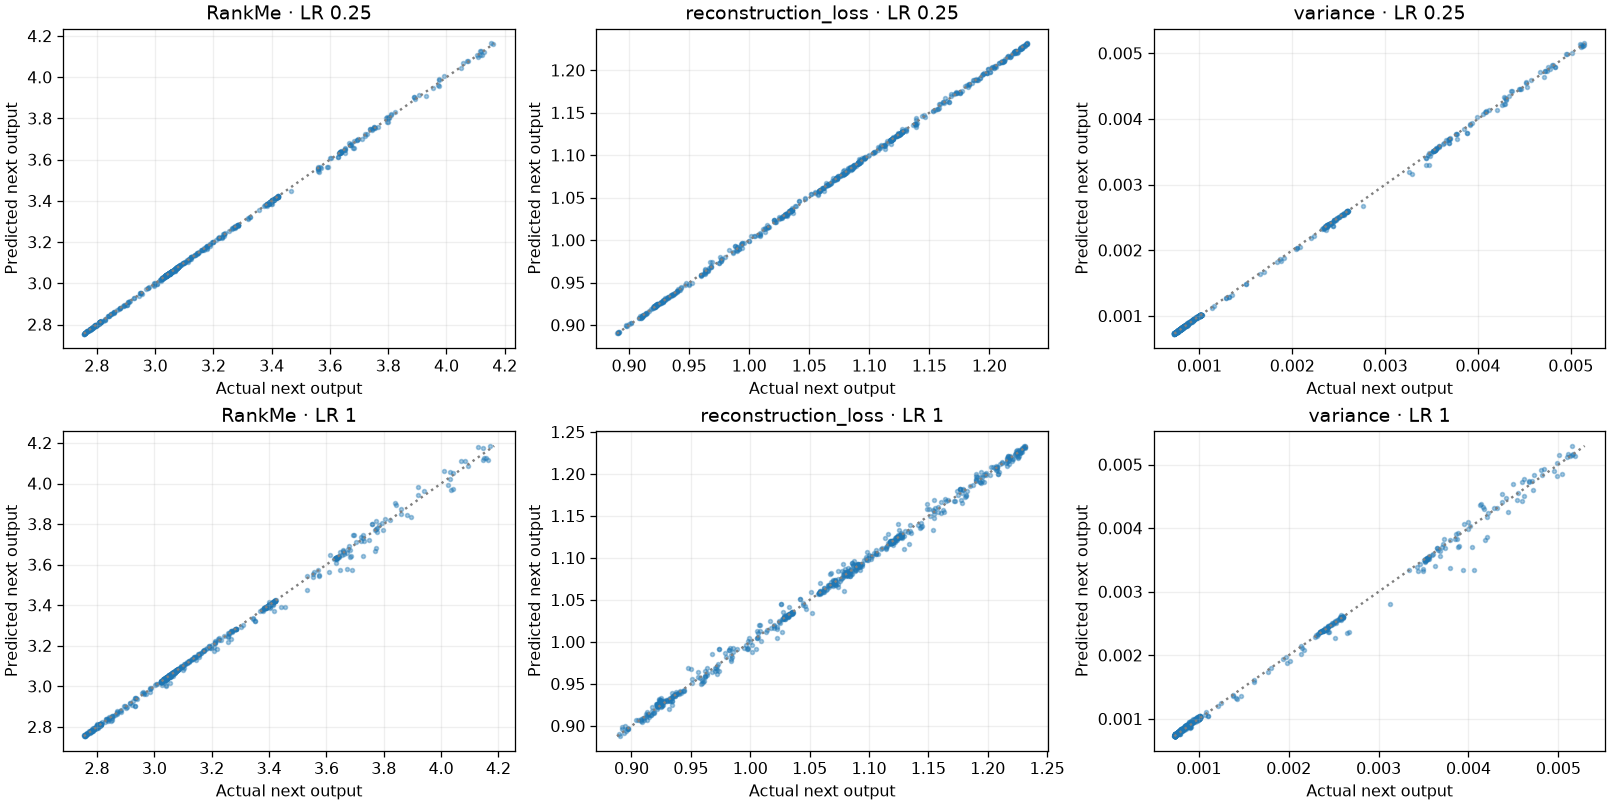



## Held-out behavior trajectories: actual versus one-step prediction

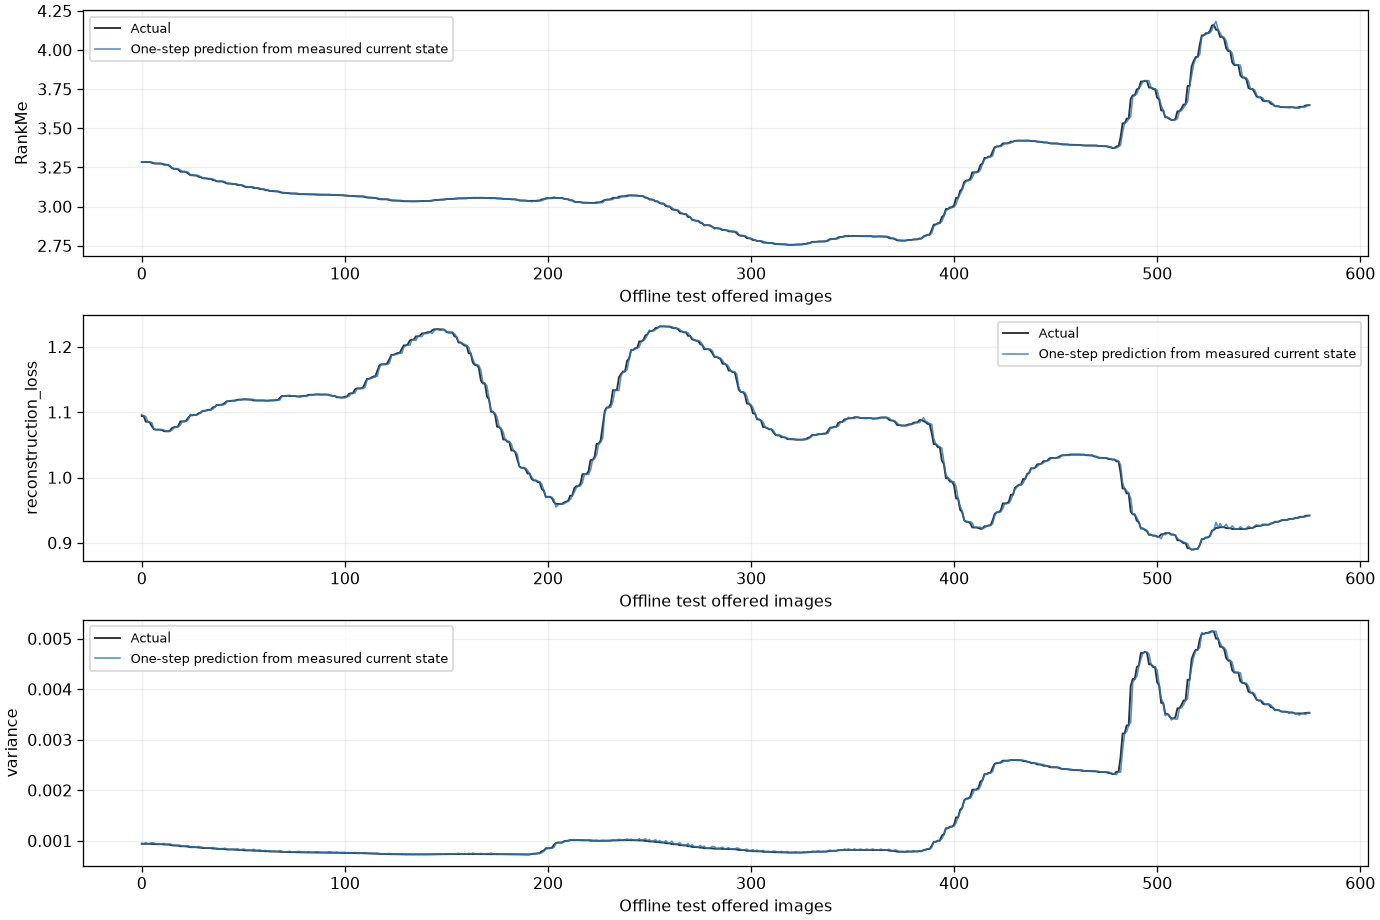

These one-step predictions receive the real current state. Free recursive forecasts are evaluated separately.

## Free-rollout error by horizon

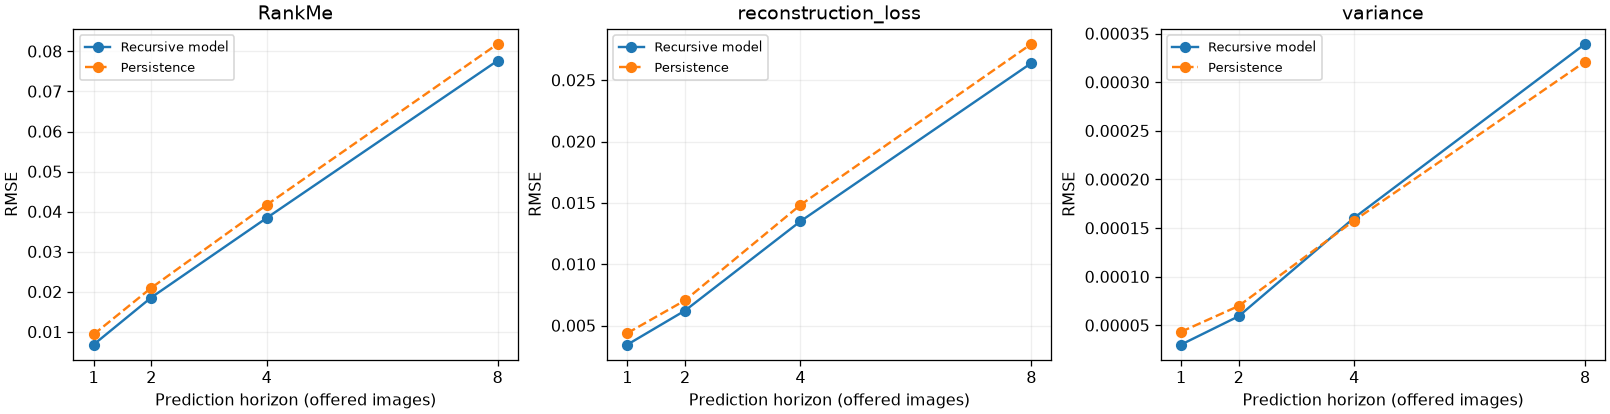

72 predeclared anchors remain within test clips. Only the initial state is measured; recorded actions are supplied and initial image statistics are held constant.

Nonphysical/nonfinite recursive forecasts by horizon: {'1': (0, 0), '2': (0, 0), '4': (0, 0), '8': (0, 0)}

## Action selection at fixed test index32

| Action | Predicted RankMe | Predicted reconstruction | Predicted variance | Predicted J |
| --- | ---: | ---: | ---: | ---: |
| 0.0 | 3.18099 | 1.1022 | 0.000858731 | 1.54495 |
| 0.25 | 3.18048 | 1.10269 | 0.000862513 | 1.54539 |
| 1.0 | 3.17715 | 1.10494 | 0.00086931 | 1.54791 |

Horizon3 minimizes accumulated original J over27 action sequences. Predicted best sequence: **[0.0, 1.0, 0.25]**; first action **0.0**. Retrospective actual cost regret against the best simulated sequence: **0.00897696**. No action is applied to the reserved91,968-image stream.


## Repeated-action rollouts from the same held-out state

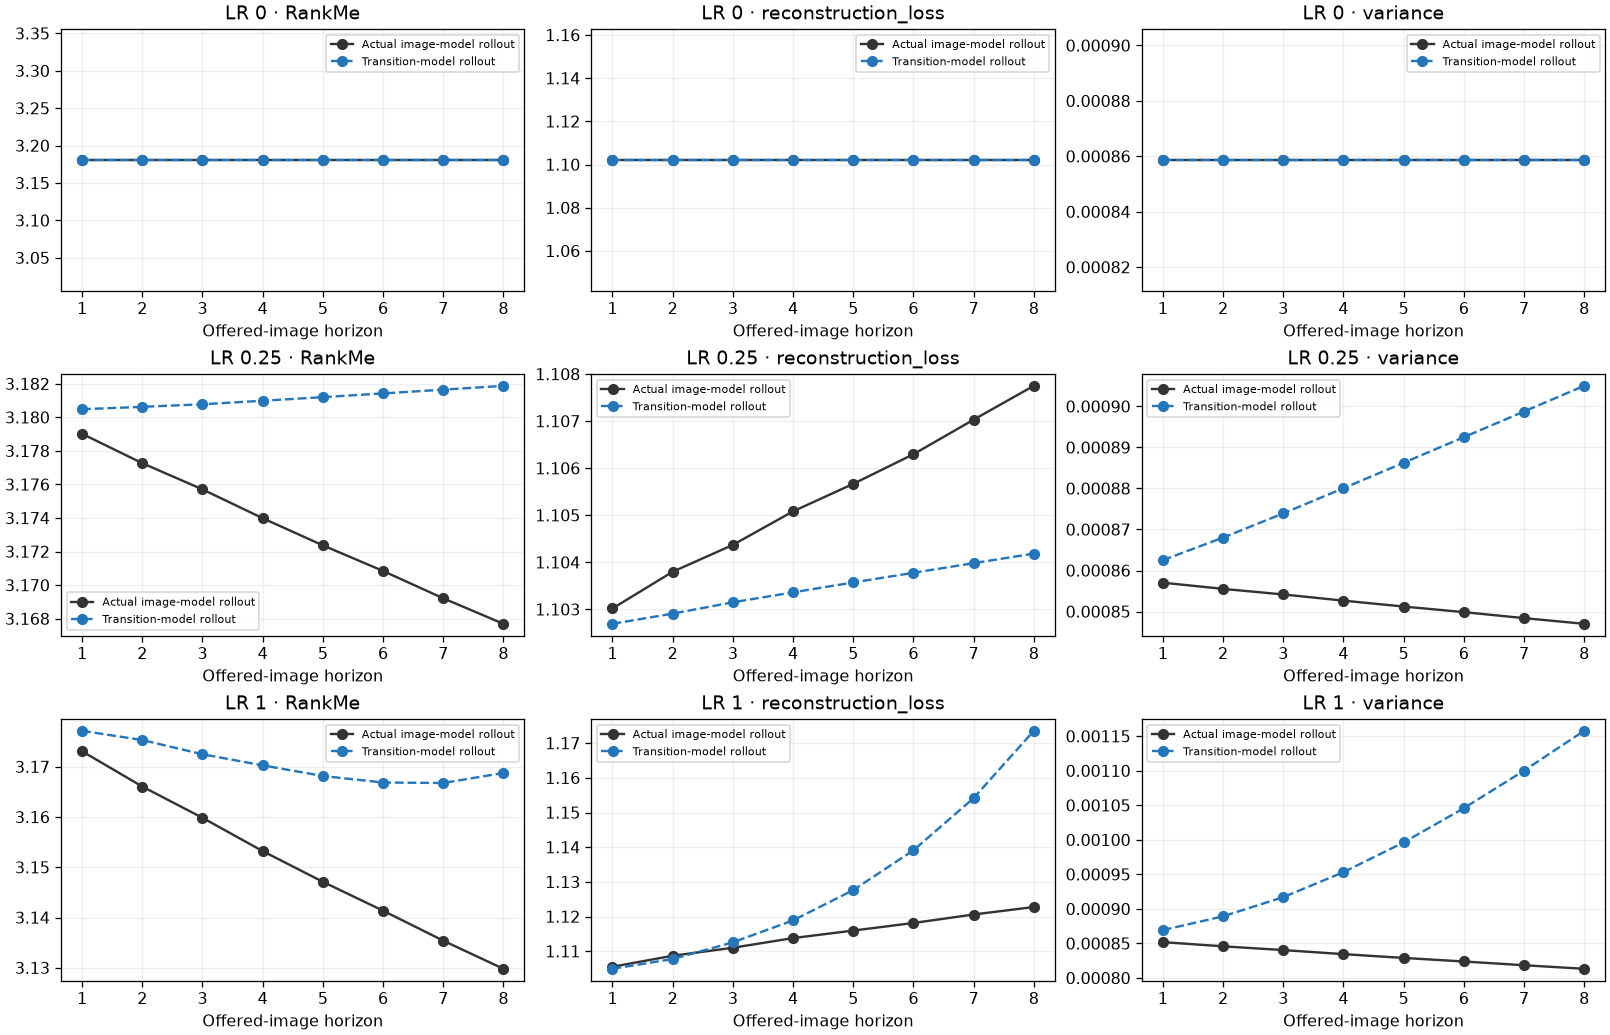

Actual image-model trajectories use subsequent recorded test images as retrospective ground truth. The learned predictor receives none of those future images.